In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
from shapely.geometry import Point
import shapely.plotting as shp_plt

from nlr_ghe_screen.clustering.milp import solve_cluster


In [2]:
rng = np.random.default_rng(42)
HOURS = np.arange(24)

buildings_raw = [
    ("residential", 50, 60, 18), ("residential", 90, 40, 22),
    ("residential", 130, 80, 15), ("residential", 70, 110, 20),
    ("residential", 110, 130, 17),
    ("office", 380, 90, 120), ("office", 420, 60, 95),
    ("office", 450, 120, 140), ("office", 400, 150, 80),
    ("retail", 340, 30, 70), ("retail", 360, 180, 85),
    ("retail", 480, 20, 60),
    ("school", 200, 300, 110), ("school", 240, 330, 90),
    ("clinic", 280, 290, 130), ("clinic", 160, 340, 100),
]

In [3]:
def gauss(center, width, height=1.0):
    d = np.minimum(np.abs(HOURS - center), 24 - np.abs(HOURS - center))
    return height * np.exp(-0.5 * (d / width) ** 2)


def base_shape(btype):
    if btype == "residential":      # morning + strong evening peak
        s = 0.25 + gauss(7.5, 1.5, 0.35) + gauss(19.5, 2.2, 0.75)
    elif btype == "office":         # plateau during working hours
        s = 0.2 + gauss(13, 3.5, 0.8)
    elif btype == "retail":         # late-morning to evening
        s = 0.25 + gauss(15, 4.0, 0.65)
    elif btype == "school":         # sharp daytime block, near-zero at night
        s = 0.1 + gauss(10.5, 2.0, 0.9)
    elif btype == "clinic":         # 24h baseload with a daytime bump
        s = 0.55 + gauss(12, 3.5, 0.35)
    else:
        raise ValueError(btype)
    return s / s.max()
 
 
def make_profile(btype, peak_kw):
    shape = base_shape(btype)
    shape = np.roll(shape, rng.integers(-1, 2))            # small time shift
    shape = shape * rng.normal(1.0, 0.04, 24)               # hourly noise
    shape = np.clip(shape, 0.02, None)
    return shape / shape.max() * peak_kw * rng.uniform(0.85, 1.1)

In [4]:
rows, profiles = [], []
for i, (btype, x, y, peak) in enumerate(buildings_raw):
    prof = make_profile(btype, peak)
    rows.append(dict(building=f"B{i:02d}", type=btype, x=x, y=y,
                     peak_kW=round(prof.max(), 1),
                     daily_kWh=round(prof.sum(), 1)))
    profiles.append(prof)

In [9]:
centroid = Point(400, 100)

buildings = pd.DataFrame(rows).set_index("building")
buildings['geometry'] = [Point(x, y) for x, y in zip(buildings['x'], buildings['y'])]
buildings = gpd.GeoDataFrame(buildings, geometry='geometry')
buildings['distance_to_centroid'] = buildings.geometry.distance(centroid)

loads = pd.DataFrame(profiles, index=buildings.index,
                     columns=[f"h{h:02d}" for h in HOURS])
centroid_load = [0] * len(loads.columns.tolist())


In [16]:
result = solve_cluster(
    loads=[centroid_load, *loads.to_numpy().tolist()],
    distances=[0, *buildings['distance_to_centroid'].tolist()],
    seed_idx=0,
    k_min=6,
    weight_peak=0.1,
    weight_net=0.1,
    weight_distance=0.8
)
result

{'total variables': 19,
 'total constraints': 51,
 'status': 'integer optimal solution',
 'objective': 0.15968102594156458,
 'best_bound': 0.15968102594156458,
 'selected': [0, 6, 7, 9, 10, 11],
 'net_curve': array([111.21687078, 105.3096667 , 102.06639591, 102.11068051,
        106.06720719, 113.66766221, 123.8558509 , 149.03218749,
        188.8435533 , 229.04969616, 289.49995793, 342.70316737,
        388.00033137, 409.17431018, 418.19400059, 415.29137014,
        378.49177084, 350.85040559, 293.86493055, 236.93196964,
        195.00918649, 164.44192242, 145.68411745, 120.82268031]),
 'peak': 418.1940005935057,
 'imbalance': 5480.179892014102,
 'total_distance': 298.72020299791416}

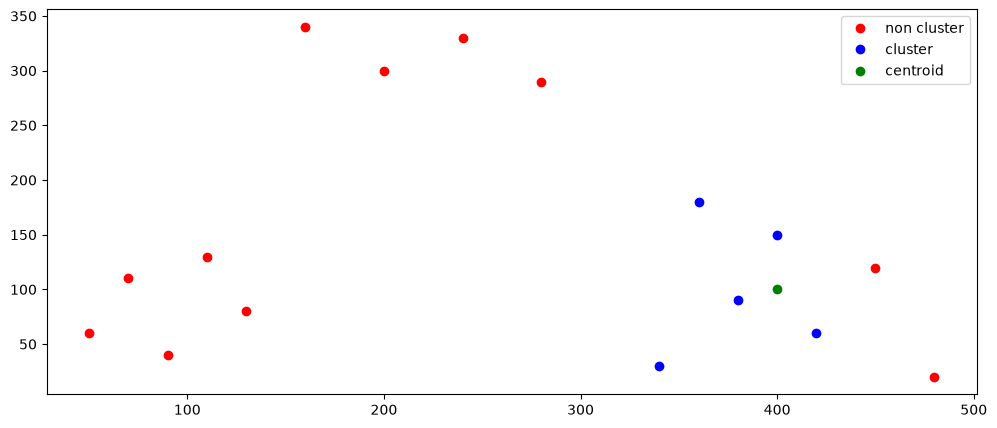

In [17]:
selected = [i - 1 for i in result['selected']][1:]

non_cluster = buildings.iloc[~np.isin(range(len(buildings)), selected)]['geometry']
cluster = buildings.iloc[selected]['geometry']
centroid = [centroid]

fig, ax = plt.subplots(figsize=(12, 5))
for points, color, label in zip([non_cluster, cluster, centroid], ['red', 'blue', 'green'], ['non cluster', 'cluster', 'centroid']):
    for point in points:
        shp_plt.plot_points(point, ax=ax, color=color, label=label)

handles, labels = ax.get_legend_handles_labels()
unique_labels_dict = dict(zip(labels, handles))
ax.legend(unique_labels_dict.values(), unique_labels_dict.keys())
plt.show()

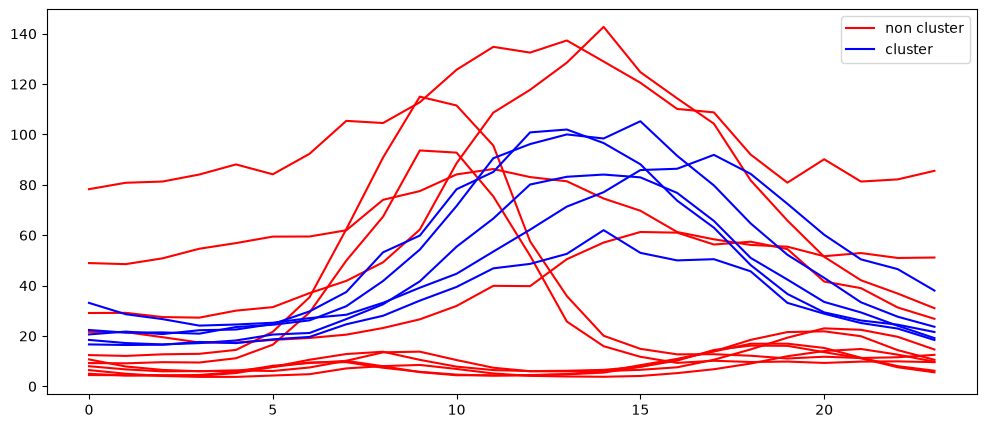

In [18]:
non_cluster_loads = loads.iloc[~np.isin(range(len(loads)), selected)].to_numpy().tolist()
cluster_loads = loads.iloc[selected].to_numpy().tolist()

fig, ax = plt.subplots(figsize=(12, 5))
for cur_loads, color, label in zip([non_cluster_loads, cluster_loads], ['red', 'blue'], ['non cluster', 'cluster']):
    for load in cur_loads:
        ax.plot(
            range(len(cluster_loads[0])),
            load,
            color=color,
            label=label
        )

handles, labels = ax.get_legend_handles_labels()
unique_labels_dict = dict(zip(labels, handles))
ax.legend(unique_labels_dict.values(), unique_labels_dict.keys())
plt.show()